# Exploratory Data Analysis (EDA)

This notebook explores the cleaned Indonesia e-commerce transaction dataset to identify patterns, trends, and business insights related to sales performance, customer transactions, product categories, geographic markets, payment methods, shipping behavior, cancellations, and product returns.

The analysis focuses on answering business-oriented questions that can support decision-making and guide the development of the final interactive dashboard.

## Analysis Objectives

The exploratory analysis aims to:

- Evaluate overall e-commerce business performance.
- Analyze sales and transaction trends over time.
- Identify high-performing product categories.
- Compare transaction performance across provinces and cities/regencies.
- Understand customer payment preferences.
- Evaluate shipping behavior and logistics costs.
- Investigate order cancellations and their main causes.
- Analyze product return patterns.
- Identify unusual transaction patterns and potential business opportunities.
- Generate actionable insights for the final dashboard.

---------

## 1. Setup & Load Cleaned Dataset

The cleaned e-commerce dataset generated during the data preparation stage is loaded for exploratory data analysis.

Before starting the analysis, several validation checks are performed to confirm that the dataset was loaded correctly and that important analytical variables have appropriate data types.

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [106]:
data_path = Path("../data/processed/cleaned_ecommerce_data.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Dataset loaded successfully.
Rows    : 20,848
Columns : 31


### Restore Datetime Columns

In [107]:
df[["order_created_at", "year_month"]].dtypes

order_created_at    object
year_month          object
dtype: object

In [108]:
df["order_created_at"] = pd.to_datetime(
    df["order_created_at"],
    errors="coerce"
)

df["year_month"] = pd.to_datetime(
    df["year_month"],
    errors="coerce"
)

In [109]:
df[["order_created_at", "year_month"]].dtypes

order_created_at    datetime64[ns]
year_month          datetime64[ns]
dtype: object

### Quick Dataset Validation

In [110]:
print("=" * 50)
print("EDA DATASET VALIDATION")
print("=" * 50)

print("\nDataset Shape:")
print(df.shape)

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Order IDs:")
print(df["order_id"].duplicated().sum())

print("\nMissing Values:")
print(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

EDA DATASET VALIDATION

Dataset Shape:
(20848, 31)

Duplicate Rows:
0

Duplicate Order IDs:
0

Missing Values:
order_created_at           1980
total_quantity                0
order_id                      0
total_returned_quantity       0
total_discount                0
product_categories            0
total_weight_gram             0
order_status                  0
cancellation_reason           0
shipping_option               0
dtype: int64


### Preview Analytical Variables

In [111]:
analysis_columns = [
    "order_id",
    "year_month",
    "total_quantity",
    "total_payment",
    "total_discount",
    "product_categories",
    "order_status_group",
    "payment_method",
    "shipping_option",
    "city_regency",
    "province",
    "buyer_shipping_cost",
    "estimated_shipping_cost",
    "has_return",
    "return_type",
    "zero_payment_flag"
]

df[analysis_columns].head()

,order_id,year_month,total_quantity,total_payment,total_discount,product_categories,order_status_group,payment_method,shipping_option,city_regency,province,buyer_shipping_cost,estimated_shipping_cost,has_return,return_type,zero_payment_flag
0,ORD_0000001,2024-04-01,2,38300,0,Celengan,Completed,Saldo ShopeePay,Reguler (Cashless)-SPX Standard,KOTA SERANG,BANTEN,0,10000,0,No Return,0
1,ORD_0000002,2024-04-01,1,18576,0,Celengan,Completed,COD (Bayar di Tempat),Hemat Kargo-SPX Hemat,KOTA SEMARANG,JAWA TENGAH,0,14500,0,No Return,0
2,ORD_0000003,2024-04-01,1,7069,0,Celengan,Completed,SeaBank Bayar Instan,Hemat Kargo-SPX Hemat,KAB. BOGOR,JAWA BARAT,0,8000,0,No Return,0
3,ORD_0000004,2024-04-01,2,32200,0,Mangkok Sambal / Saus,Completed,COD (Bayar di Tempat),Hemat Kargo-SPX Hemat,KOTA JAMBI,JAMBI,0,20000,0,No Return,0
4,ORD_0000005,2024-04-01,3,0,0,"Keranjang, Other, Tempat Nasi",Cancelled,COD (Bayar di Tempat),Hemat Kargo-SPX Hemat,KOTA TANGERANG,BANTEN,0,8000,0,No Return,0


### Dataset Preparation for EDA

The cleaned dataset contains 20,848 transaction records and 31 variables.

Initial validation confirmed that no exact duplicate records or duplicated order IDs are present. The remaining missing values in `order_created_at` correspond to transactions whose exact timestamps could not be reliably reconstructed during data preparation.

For time-based analysis, the `year_month` variable provides recovered monthly information and allows these transactions to remain included in temporal analysis.

The dataset is therefore ready for exploratory analysis.

------------

## 2. Business Performance Overview

This section provides a high-level overview of the e-commerce business performance.

The analysis begins by examining the distribution of transaction statuses before calculating the main business KPIs. This distinction is important because not all recorded orders represent completed transactions.

The main metrics analyzed include:

- Total Orders
- Completed Orders
- Cancelled Orders
- Orders in Progress
- Completion Rate
- Cancellation Rate
- Total Payment Value
- Average Order Value
- Total Items Purchased
- Total Returned Items
- Return Rate

In [112]:
status_summary = (
    df["order_status_group"]
    .value_counts()
    .rename_axis("order_status")
    .reset_index(name="total_orders")
)

status_summary["percentage"] = (
    status_summary["total_orders"]
    / len(df)
    * 100
).round(2)

status_summary

,order_status,total_orders,percentage
0,Completed,17929,86.00
1,Cancelled,2830,13.57
2,In Progress,89,0.43


### Order Status Overview

The dataset contains 20,848 orders, of which 17,929 (86.00%) were completed, 2,830 (13.57%) were cancelled, and 89 (0.43%) were still in progress.

Completed orders represent the majority of transactions. However, cancelled orders account for 13.57% of all recorded orders, making cancellation behavior an important area for further investigation.

For the following business performance analysis, completed transactions will be separated from cancelled and in-progress orders when calculating metrics that are intended to represent realized transaction activity.

### Completed Transaction Dataset

To evaluate realized transaction performance, a separate subset containing only completed orders is created.

This prevents cancelled or still-in-progress transactions from affecting metrics such as total payment value, average order value, and completed item volume.

In [113]:
completed_orders = df[
    df["order_status_group"] == "Completed"
].copy()

print(f"All Orders       : {len(df):,}")
print(f"Completed Orders : {len(completed_orders):,}")

All Orders       : 20,848
Completed Orders : 17,929


### Calculate Business KPIs

In [114]:
total_orders = len(df)
completed_count = len(completed_orders)
cancelled_count = (df["order_status_group"] == "Cancelled").sum()
in_progress_count = (df["order_status_group"] == "In Progress").sum()

completion_rate = completed_count / total_orders * 100
cancellation_rate = cancelled_count / total_orders * 100

total_payment_value = completed_orders["total_payment"].sum()
average_order_value = completed_orders["total_payment"].mean()

total_items_purchased = completed_orders["total_quantity"].sum()
total_returned_items = completed_orders["total_returned_quantity"].sum()

return_rate = (
    total_returned_items / total_items_purchased * 100
)

business_kpis = pd.DataFrame({
    "metric": [
        "Total Orders",
        "Completed Orders",
        "Cancelled Orders",
        "Orders In Progress",
        "Completion Rate (%)",
        "Cancellation Rate (%)",
        "Total Payment Value",
        "Average Order Value",
        "Total Items Purchased",
        "Total Returned Items",
        "Item Return Rate (%)"
    ],
    "value": [
        total_orders,
        completed_count,
        cancelled_count,
        in_progress_count,
        completion_rate,
        cancellation_rate,
        total_payment_value,
        average_order_value,
        total_items_purchased,
        total_returned_items,
        return_rate
    ]
})

business_kpis

,metric,value
0,Total Orders,"20,848.00"
1,Completed Orders,"17,929.00"
2,Cancelled Orders,"2,830.00"
3,Orders In Progress,89.00
4,Completion Rate (%),86.00
5,Cancellation Rate (%),13.57
6,Total Payment Value,"1,051,466,307.00"
7,Average Order Value,"58,646.12"
8,Total Items Purchased,"44,546.00"
9,Total Returned Items,370.00


### Business KPI Summary

The business performance overview provides the following key findings:

- A total of **20,848 orders** were recorded in the dataset.
- **17,929 orders (86.00%)** were successfully completed.
- **2,830 orders (13.57%)** were cancelled, while only **89 orders (0.43%)** remained in progress.
- Completed transactions generated approximately **IDR 1.05 billion in total payment value**.
- The **average payment value per completed order** was approximately **IDR 58.6 thousand**.
- Completed transactions contained **44,546 purchased items**.
- A total of **370 items were returned**, representing an **item return rate of approximately 0.83%**.

Overall, the dataset shows a high order completion rate and a relatively low item return rate. However, the cancellation rate of 13.57% represents a notable share of all orders and should be investigated further to identify its main drivers.

These metrics establish the baseline business performance that will be used for subsequent trend, product, geographic, payment, shipping, cancellation, and return analyses.

------------------

## 3. Sales & Order Trend Analysis

This section examines how completed transaction activity changes over time.

Monthly trends are analyzed using the `year_month` variable, which preserves monthly information for transactions whose exact order timestamps were unavailable.

The analysis focuses on:

- Monthly completed orders
- Monthly total payment value
- Monthly average order value
- Monthly purchased item volume
- Month-over-month changes in transaction performance

### Monthly Performance

In [115]:
monthly_performance = (
    completed_orders
    .groupby("year_month")
    .agg(
        completed_orders=("order_id", "count"),
        total_payment_value=("total_payment", "sum"),
        average_order_value=("total_payment", "mean"),
        total_items=("total_quantity", "sum")
    )
    .reset_index()
    .sort_values("year_month")
)

monthly_performance

,year_month,completed_orders,total_payment_value,average_order_value,total_items
0,2023-12-01,352,23850125,"67,756.04",841
1,2024-01-01,367,24492481,"66,737.01",1069
2,2024-02-01,327,21141376,"64,652.53",835
3,2024-03-01,389,30259734,"77,788.52",1658
4,2024-04-01,403,21260662,"52,755.99",1099
5,2024-05-01,525,35530574,"67,677.28",1124
6,2024-06-01,608,32465925,"53,397.90",1469
7,2024-07-01,1114,63791545,"57,263.51",2745
8,2024-08-01,1097,65939126,"60,108.59",2784
9,2024-09-01,967,71193097,"73,622.64",2497


#### Monthly Performance Summary

The monthly performance table summarizes completed transaction activity from December 2023 to November 2025.

For each month, four main business metrics are calculated:

- **Completed Orders:** Number of successfully completed transactions.
- **Total Payment Value:** Total realized payment value generated from completed orders.
- **Average Order Value:** Average payment value generated per completed transaction.
- **Total Items:** Total quantity of items purchased through completed transactions.

Only completed orders are included in this analysis to ensure that cancelled and in-progress transactions do not affect realized business performance.

The monthly aggregation shows noticeable variation in transaction activity across the observation period. Completed order volume generally increased during several periods in 2024 and 2025, while total payment value and average order value did not always move proportionally with order volume.

These monthly metrics will therefore be analyzed further through trend visualization to identify changes in transaction volume, payment value, and customer spending behavior over time.

----------

### Monthly Completed Orders Trend

The monthly number of completed orders is visualized to examine changes in transaction volume over time and identify periods of growth, decline, or unusual activity.

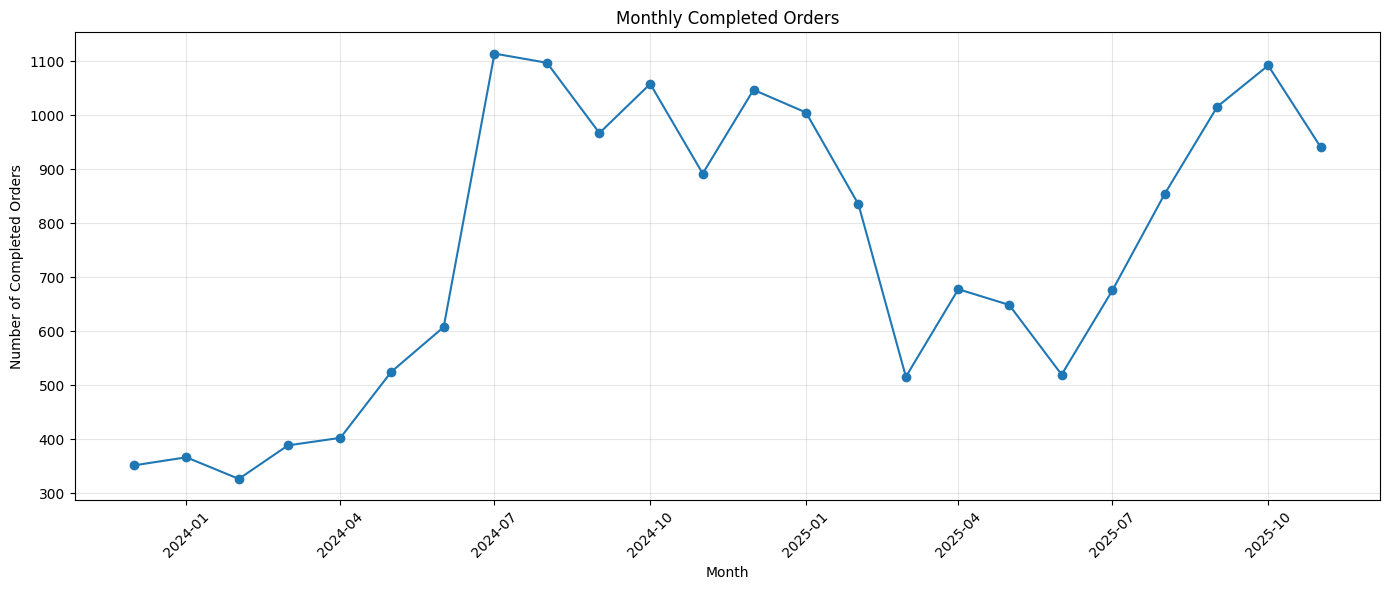

In [116]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["completed_orders"],
    marker="o"
)

plt.title("Monthly Completed Orders")
plt.xlabel("Month")
plt.ylabel("Number of Completed Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Monthly Total Payment Value Trend

Monthly total payment value is analyzed alongside order volume to determine whether changes in transaction activity are accompanied by similar changes in realized payment value.

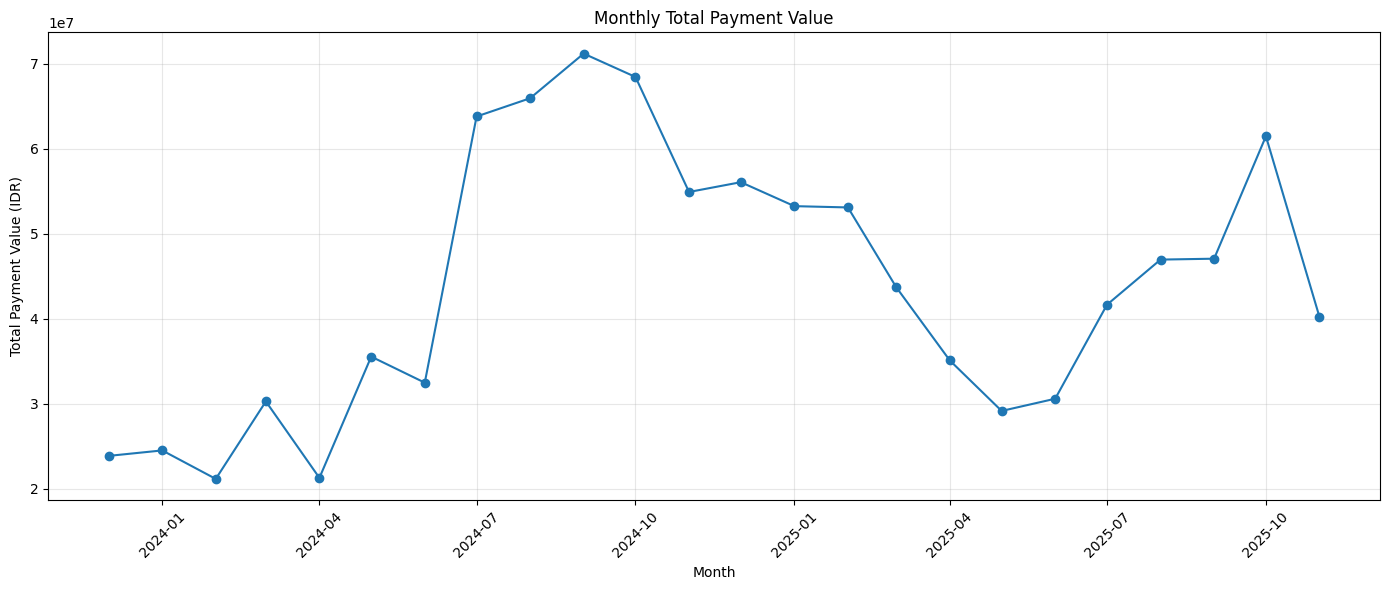

In [117]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["total_payment_value"],
    marker="o"
)

plt.title("Monthly Total Payment Value")
plt.xlabel("Month")
plt.ylabel("Total Payment Value (IDR)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Monthly Performance Interpretation

The monthly trend shows substantial changes in completed transaction activity throughout the observation period.

Completed orders were relatively low during the early months, before increasing sharply and reaching 1,114 completed orders in July 2024. Transaction volume remained relatively high throughout the second half of 2024 before declining during early 2025, reaching 516 completed orders in March 2025.

After this decline, completed order volume gradually recovered and reached 1,092 orders in October 2025 before decreasing to 941 orders in November 2025.

Total payment value generally follows a similar pattern to completed order volume. However, the movements are not always proportional. For example, some months with lower transaction volume still generated relatively high payment values, indicating differences in the average monetary value of individual orders.

This suggests that overall business performance is influenced by both transaction volume and the value generated per transaction. Therefore, Average Order Value (AOV) should be examined separately to better understand changes in customer spending behavior over time.

---

### Monthly Average Order Value Trend

Average Order Value (AOV) represents the average payment value generated per completed transaction.

Analyzing AOV over time helps determine whether changes in total payment value are primarily driven by transaction volume or by changes in the monetary value of individual orders.

A higher AOV indicates that completed transactions generated more payment value on average, while a lower AOV indicates that the business relied more heavily on transaction volume to generate total payment value.

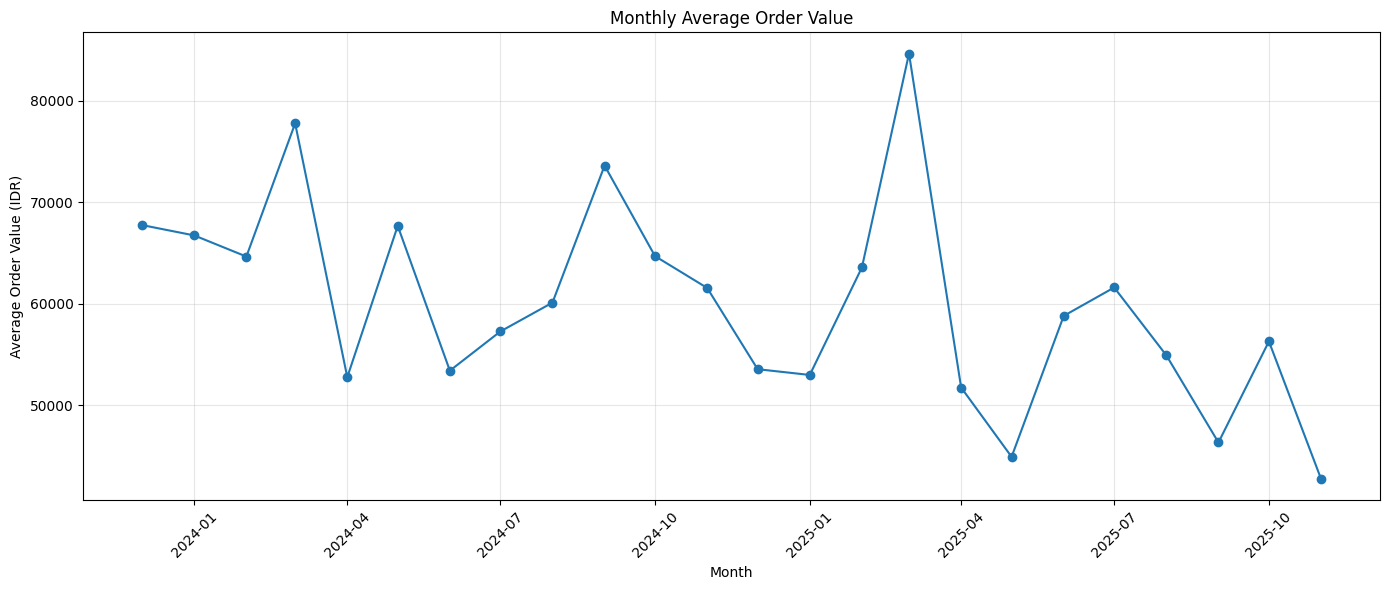

In [118]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["average_order_value"],
    marker="o"
)

plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("Average Order Value (IDR)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Average Order Value Interpretation

Average Order Value (AOV) fluctuated considerably throughout the observation period, indicating that changes in total payment value were not driven solely by the number of completed orders.

The highest monthly AOV occurred in March 2025 at approximately IDR 84,670 per completed order, despite the month recording only 516 completed orders. Another relatively high AOV was observed in March 2024 at approximately IDR 77,789.

In contrast, several months with high transaction volumes recorded lower AOV. For example, September 2025 recorded 1,016 completed orders but an AOV of approximately IDR 46,316.

By November 2025, AOV decreased further to approximately IDR 42,724, the lowest level observed in the dataset.

These results show that higher transaction volume does not necessarily correspond to higher value per transaction. Therefore, both order volume and AOV should be considered when evaluating monthly business performance.

--------------

### Month-over-Month Performance Growth

Month-over-Month (MoM) growth is calculated to measure how completed order volume and total payment value changed relative to the previous month.

This analysis helps identify periods of rapid growth or decline and provides a clearer view of short-term changes in business performance.

In [119]:
monthly_performance["order_growth_pct"] = (
    monthly_performance["completed_orders"]
    .pct_change(fill_method=None)
    .mul(100)
)

monthly_performance["payment_growth_pct"] = (
    monthly_performance["total_payment_value"]
    .pct_change(fill_method=None)
    .mul(100)
)

monthly_performance[
    [
        "year_month",
        "completed_orders",
        "order_growth_pct",
        "total_payment_value",
        "payment_growth_pct"
    ]
].round(2)

,year_month,completed_orders,order_growth_pct,total_payment_value,payment_growth_pct
0,2023-12-01,352,NaN,23850125,NaN
1,2024-01-01,367,4.26,24492481,2.69
2,2024-02-01,327,-10.90,21141376,-13.68
3,2024-03-01,389,18.96,30259734,43.13
4,2024-04-01,403,3.60,21260662,-29.74
5,2024-05-01,525,30.27,35530574,67.12
6,2024-06-01,608,15.81,32465925,-8.63
7,2024-07-01,1114,83.22,63791545,96.49
8,2024-08-01,1097,-1.53,65939126,3.37
9,2024-09-01,967,-11.85,71193097,7.97


#### Month-over-Month Growth Interpretation

Month-over-Month analysis reveals substantial fluctuations in both completed order volume and total payment value throughout the observation period.

The strongest monthly expansion occurred in July 2024, when completed orders increased by 83.22% compared with the previous month, while total payment value increased by 96.49%. This represents the most significant simultaneous increase in transaction volume and payment value observed in the dataset.

The largest decline in completed order volume occurred in March 2025, with orders decreasing by 38.20%. However, total payment value declined by only 17.70%. This difference is consistent with the relatively high Average Order Value observed during March 2025.

Order volume and payment value did not always move in the same direction. In April 2025, completed orders increased by 31.40%, while total payment value decreased by 19.71%. This indicates that the recovery in transaction volume was accompanied by lower average value per transaction.

Another divergence occurred in October 2025, when completed orders increased by 7.48% while total payment value increased by 30.62%.

Overall, the results demonstrate that changes in transaction volume alone are not sufficient to explain monthly business performance. Order volume, total payment value, and Average Order Value should therefore be evaluated together.

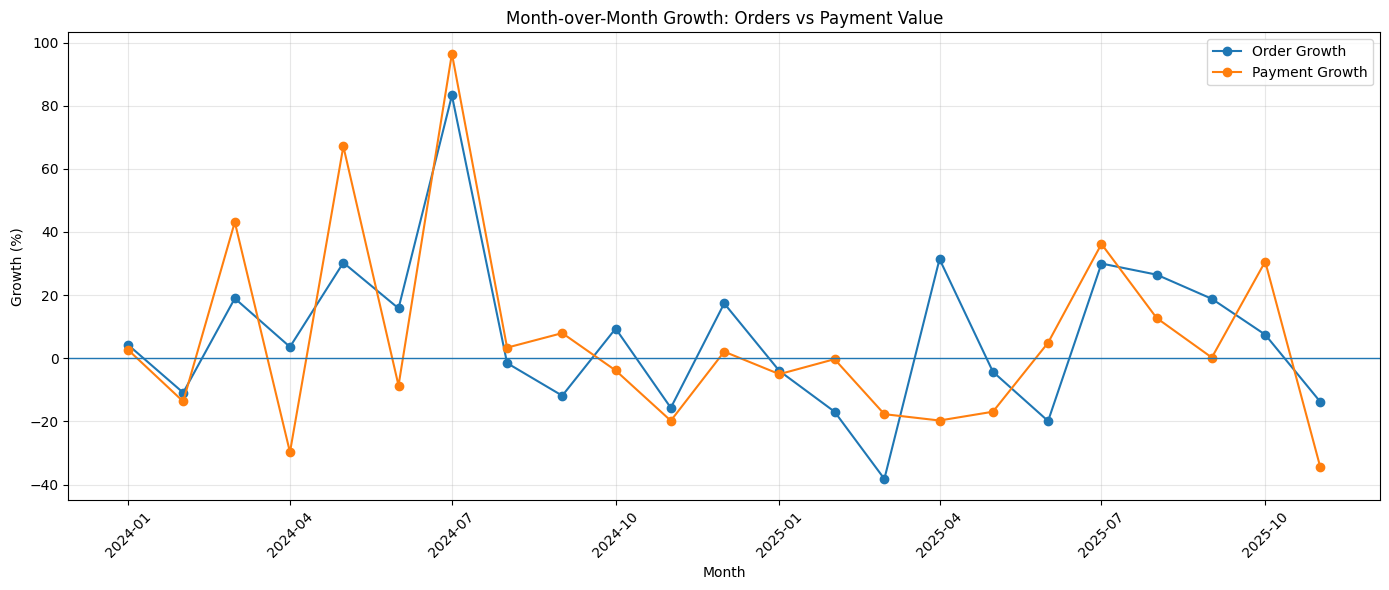

In [120]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["order_growth_pct"],
    marker="o",
    label="Order Growth"
)

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["payment_growth_pct"],
    marker="o",
    label="Payment Growth"
)

plt.axhline(0, linewidth=1)

plt.title("Month-over-Month Growth: Orders vs Payment Value")
plt.xlabel("Month")
plt.ylabel("Growth (%)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Monthly Performance Conclusion

The monthly analysis shows that business performance fluctuated considerably throughout the observation period.

Although completed order volume and total payment value often moved in similar directions, several months showed substantial differences between their growth rates. These differences are partly reflected in changes in Average Order Value, indicating that transaction volume and value per transaction contribute differently to monthly performance.

The results highlight the importance of evaluating completed orders, total payment value, and Average Order Value together rather than relying on transaction volume alone.

Further analysis will examine the underlying business dimensions that may contribute to these patterns, including product categories, payment methods, geographic distribution, shipping options, cancellations, and returns.

-------------

## 4. Product & Category Performance Analysis

This section analyzes the product categories associated with completed transactions to identify categories that contribute most to transaction activity and examine their return behavior.

Before calculating category-level metrics, the structure of the `product_categories` variable is examined because a single order may contain products from multiple categories.

In [121]:
completed_orders[
    ["order_id", "product_categories", "num_product_categories"]
].head(20)

,order_id,product_categories,num_product_categories
0,ORD_0000001,Celengan,1
1,ORD_0000002,Celengan,1
2,ORD_0000003,Celengan,1
3,ORD_0000004,Mangkok Sambal / Saus,1
5,ORD_0000006,Celengan,1
7,ORD_0000008,Celengan,1
9,ORD_0000010,"Aksesoris Mandi, Celengan, Keranjang",3
12,ORD_0000013,Toples / Sealware,1
13,ORD_0000014,Mangkok Sambal / Saus,1
15,ORD_0000016,Celengan,1


In [122]:
completed_orders["num_product_categories"].value_counts().sort_index()

num_product_categories
1     16633
2       862
3       282
4        87
5        39
6        14
7         8
8         2
9         1
11        1
Name: count, dtype: int64

#### Category Structure

Most completed orders contain only one product category, with 16,633 out of 17,929 completed orders classified as single-category transactions.

A smaller portion of orders contains multiple product categories, ranging from 2 to 11 categories per order. Therefore, multi-category transactions need to be separated before performing category-level analysis.

-----

### Preparing Category-Level Data

Most completed orders contain a single product category, although some transactions contain products from multiple categories.

Because multiple categories are stored within the `product_categories` column as comma-separated values, directly grouping by this column would incorrectly treat category combinations as separate categories.

Therefore, a separate category-level dataset is created by splitting multi-category values and expanding them into individual rows. This allows each category appearing in an order to be analyzed independently while preserving the original transaction dataset.

In [123]:
category_orders = completed_orders.copy()

category_orders["product_category"] = (
    category_orders["product_categories"]
    .str.split(",")
)

category_orders = category_orders.explode("product_category")

category_orders["product_category"] = (
    category_orders["product_category"]
    .str.strip()
)

print("Completed orders:", len(completed_orders))
print("Category-level records:", len(category_orders))
print("Unique categories:", category_orders["product_category"].nunique())

category_orders[
    ["order_id", "product_categories", "product_category"]
].head(20)

Completed orders: 17929
Category-level records: 19922
Unique categories: 38


,order_id,product_categories,product_category
0,ORD_0000001,Celengan,Celengan
1,ORD_0000002,Celengan,Celengan
2,ORD_0000003,Celengan,Celengan
3,ORD_0000004,Mangkok Sambal / Saus,Mangkok Sambal / Saus
5,ORD_0000006,Celengan,Celengan
7,ORD_0000008,Celengan,Celengan
9,ORD_0000010,"Aksesoris Mandi, Celengan, Keranjang",Aksesoris Mandi
9,ORD_0000010,"Aksesoris Mandi, Celengan, Keranjang",Celengan
9,ORD_0000010,"Aksesoris Mandi, Celengan, Keranjang",Keranjang
12,ORD_0000013,Toples / Sealware,Toples / Sealware


### Category Popularity

Category popularity is analyzed based on the number of completed orders containing each product category.

Since multi-category transactions have been expanded into separate category-level records, each category can now be counted independently. This analysis identifies the product categories that appear most frequently in completed transactions.

In [124]:
category_popularity = (
    category_orders
    .groupby("product_category")
    .agg(
        completed_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("completed_orders", ascending=False)
)

category_popularity["order_share_pct"] = (
    category_popularity["completed_orders"]
    / len(completed_orders)
    * 100
).round(2)

category_popularity.head(15)

,product_category,completed_orders,order_share_pct
7,Celengan,5207,29.04
14,Mangkok Sambal / Saus,3480,19.41
3,Aksesoris Pintu,2689,15.00
15,Nampan / Tray,1295,7.22
16,Other,730,4.07
5,Baskom / Mangkok Besar,636,3.55
11,Keranjang,586,3.27
29,Seal / Baut / Roof,583,3.25
26,Rak / Rak Serbaguna,462,2.58
12,Lunch Box / Rantang,454,2.53


#### Top Product Categories

The most frequently purchased product categories are visualized to identify which categories contribute most strongly to completed transaction activity.

Because an order may contain multiple product categories, the percentage represents the share of completed orders containing each category rather than a mutually exclusive distribution.

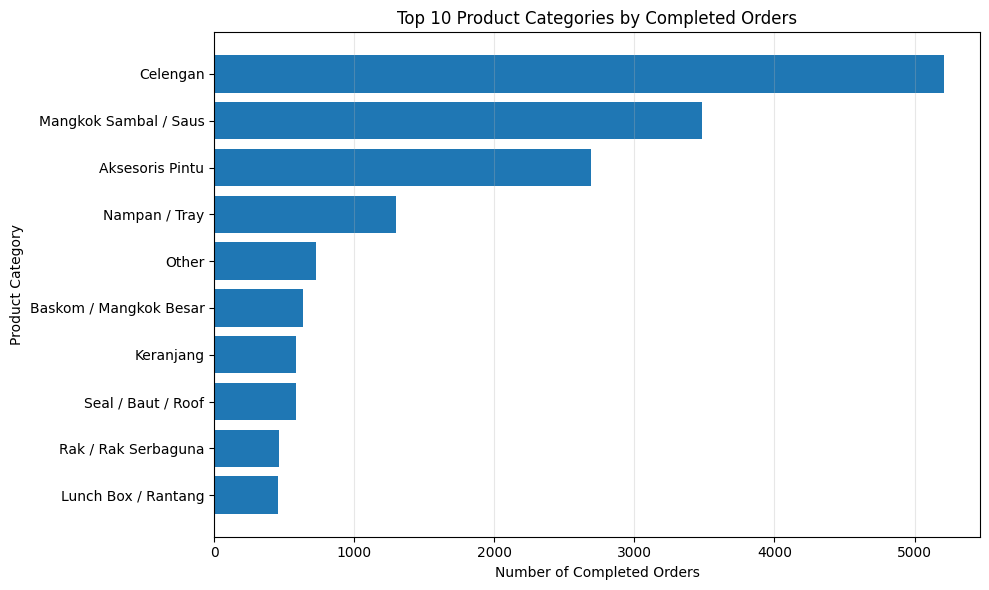

In [125]:
top_categories = category_popularity.head(10).sort_values(
    "completed_orders",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["product_category"],
    top_categories["completed_orders"]
)

plt.title("Top 10 Product Categories by Completed Orders")
plt.xlabel("Number of Completed Orders")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Category Popularity Insights

Product category popularity is highly concentrated among several categories.

- **Celengan** is the most frequently appearing category, occurring in **5,207 completed orders (29.04%)**.
- **Mangkok Sambal / Saus** ranks second with **3,480 orders (19.41%)**, followed by **Aksesoris Pintu** with **2,689 orders (15.00%)**.
- After the top three categories, order frequency decreases substantially, with **Nampan / Tray** appearing in only **7.22%** of completed orders.
- This indicates that transaction activity is primarily concentrated in a relatively small number of product categories.

Because a single order may contain multiple product categories, these percentages should be interpreted as the proportion of completed orders containing each category rather than as mutually exclusive market shares.

---

### Category Transaction Value

Category popularity shows how frequently each product category appears in completed orders, but frequency alone does not indicate its contribution to transaction value.

Since a single order may contain multiple product categories while `total_payment` is recorded at the order level, directly summing `total_payment` after expanding the categories would result in double counting.

To avoid this, the total payment of each order is allocated equally across the product categories contained in that order. This provides an estimated category-level transaction value while preserving the total payment value of completed transactions.

**Make allocated payment**

In [126]:
category_orders["allocated_payment"] = (
    category_orders["total_payment"]
    / category_orders["num_product_categories"]
)

category_orders[
    [
        "order_id",
        "product_category",
        "num_product_categories",
        "total_payment",
        "allocated_payment"
    ]
].head(15)

,order_id,product_category,num_product_categories,total_payment,allocated_payment
0,ORD_0000001,Celengan,1,38300,"38,300.00"
1,ORD_0000002,Celengan,1,18576,"18,576.00"
2,ORD_0000003,Celengan,1,7069,"7,069.00"
3,ORD_0000004,Mangkok Sambal / Saus,1,32200,"32,200.00"
5,ORD_0000006,Celengan,1,40996,"40,996.00"
7,ORD_0000008,Celengan,1,18280,"18,280.00"
9,ORD_0000010,Aksesoris Mandi,3,92800,"30,933.33"
9,ORD_0000010,Celengan,3,92800,"30,933.33"
9,ORD_0000010,Keranjang,3,92800,"30,933.33"
12,ORD_0000013,Toples / Sealware,1,32200,"32,200.00"


**Validate**

In [127]:
original_payment = completed_orders["total_payment"].sum()
allocated_payment = category_orders["allocated_payment"].sum()

print(f"Original completed payment : {original_payment:,.0f}")
print(f"Allocated category payment : {allocated_payment:,.0f}")
print(f"Difference                 : {allocated_payment - original_payment:,.2f}")

Original completed payment : 1,051,466,307
Allocated category payment : 1,051,466,307
Difference                 : 0.00


**Make Category Value Summary**

In [128]:
category_value = (
    category_orders
    .groupby("product_category")
    .agg(
        completed_orders=("order_id", "nunique"),
        estimated_transaction_value=("allocated_payment", "sum"),
        average_allocated_value=("allocated_payment", "mean")
    )
    .reset_index()
    .sort_values("estimated_transaction_value", ascending=False)
)

category_value["value_share_pct"] = (
    category_value["estimated_transaction_value"]
    / completed_orders["total_payment"].sum()
    * 100
).round(2)

category_value.head(15)

,product_category,completed_orders,estimated_transaction_value,average_allocated_value,value_share_pct
29,Seal / Baut / Roof,583,"277,746,919.83","476,409.81",26.42
7,Celengan,5207,"155,068,499.45","29,780.78",14.75
14,Mangkok Sambal / Saus,3480,"136,388,226.57","39,192.02",12.97
15,Nampan / Tray,1295,"102,852,082.65","79,422.46",9.78
12,Lunch Box / Rantang,454,"47,953,005.58","105,623.36",4.56
16,Other,730,"47,883,004.80","65,593.16",4.55
5,Baskom / Mangkok Besar,636,"39,835,880.63","62,635.03",3.79
3,Aksesoris Pintu,2689,"38,872,022.02","14,455.94",3.70
26,Rak / Rak Serbaguna,462,"33,892,586.77","73,360.58",3.22
21,Perlengkapan Packing,275,"20,091,864.62","73,061.33",1.91


**Visualisasi Top 10**

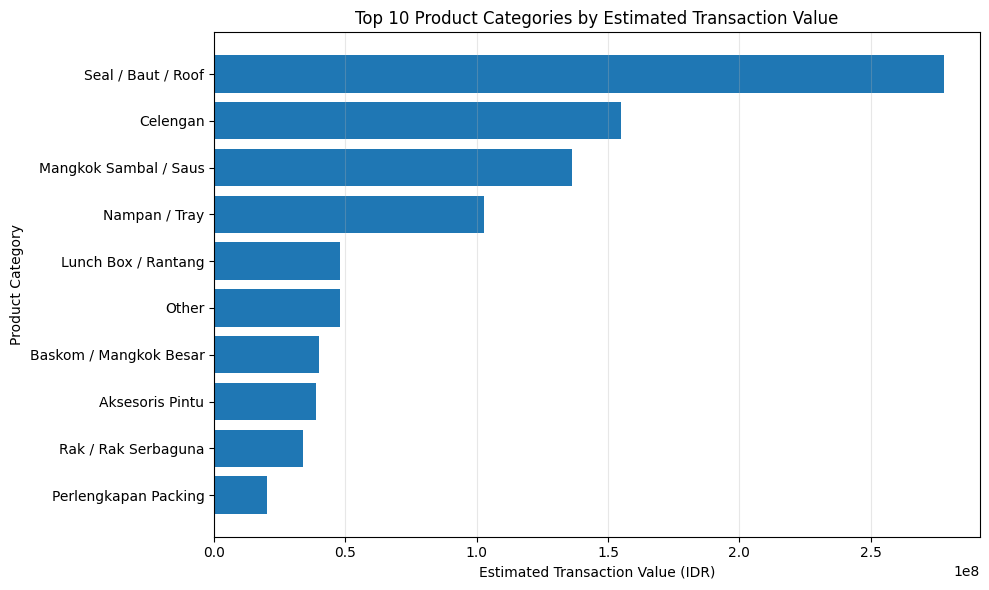

In [129]:
top_category_value = (
    category_value
    .head(10)
    .sort_values("estimated_transaction_value")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_category_value["product_category"],
    top_category_value["estimated_transaction_value"]
)

plt.title("Top 10 Product Categories by Estimated Transaction Value")
plt.xlabel("Estimated Transaction Value (IDR)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Category Transaction Value Insights

The category-level transaction value analysis reveals a different pattern from category popularity.

- **Seal / Baut / Roof** generates the highest estimated transaction value at approximately **IDR 277.5 million**, representing **26.42%** of completed transaction value, despite appearing in only **583 completed orders**.
- **Celengan**, the most frequently purchased category with 5,207 completed orders, ranks second in estimated transaction value at approximately **IDR 155.1 million (14.75%)**.
- **Mangkok Sambal / Saus** ranks third with approximately **IDR 136.4 million (12.97%)**, followed by **Nampan / Tray** at approximately **IDR 102.9 million (9.78%)**.
- The difference between order frequency and transaction value indicates that highly popular categories are not necessarily the categories generating the highest monetary value.
- In particular, **Seal / Baut / Roof** appears to represent a relatively high-value category, with an average allocated transaction value substantially higher than the most frequently purchased categories.

These values are estimated using equal allocation of each order's total payment across its associated product categories. Therefore, the results should be interpreted as estimated category-level contribution rather than exact product-level revenue.

---------------------

### Category Return Behavior

Return behavior is analyzed to identify product categories that are frequently associated with completed orders containing returned items.

Because returned quantities are recorded at the order level and the dataset does not specify which individual product category was returned in multi-category transactions, returns cannot be attributed directly to a specific category with certainty.

Therefore, this analysis measures the proportion of completed orders containing each category that were associated with at least one returned item. The resulting metric is interpreted as a **return-associated order rate**, rather than an exact product-level return rate.

In [130]:
category_return_base = (
    category_orders[
        ["order_id", "product_category", "has_return"]
    ]
    .drop_duplicates()
)

category_returns = (
    category_return_base
    .groupby("product_category")
    .agg(
        completed_orders=("order_id", "nunique"),
        orders_with_return=("has_return", "sum")
    )
    .reset_index()
)

category_returns["return_associated_rate_pct"] = (
    category_returns["orders_with_return"]
    / category_returns["completed_orders"]
    * 100
).round(2)

category_returns.sort_values(
    "return_associated_rate_pct",
    ascending=False
).head(15)

,product_category,completed_orders,orders_with_return,return_associated_rate_pct
27,Sapu / Pembersih Lantai,85,8,9.41
31,Spatula,68,6,8.82
1,Aksesoris Mandi,46,4,8.70
9,Gantungan Baju / Hanger,115,7,6.09
37,Toples / Sealware,152,8,5.26
24,Plastik / Wadah Plastik,211,11,5.21
30,Sikat / Pembersih,61,3,4.92
23,Pisau / Alat Potong,135,6,4.44
6,Botol / Gelas / Mug,376,16,4.26
32,Stempel / Alat Kantor,97,4,4.12


In [131]:
# Filter categories with sufficient transaction volume
min_orders = 50

category_returns_filtered = (
    category_returns[
        category_returns["completed_orders"] >= min_orders
    ]
    .sort_values(
        "return_associated_rate_pct",
        ascending=False
    )
)

category_returns_filtered.head(10)

,product_category,completed_orders,orders_with_return,return_associated_rate_pct
27,Sapu / Pembersih Lantai,85,8,9.41
31,Spatula,68,6,8.82
9,Gantungan Baju / Hanger,115,7,6.09
37,Toples / Sealware,152,8,5.26
24,Plastik / Wadah Plastik,211,11,5.21
30,Sikat / Pembersih,61,3,4.92
23,Pisau / Alat Potong,135,6,4.44
6,Botol / Gelas / Mug,376,16,4.26
32,Stempel / Alat Kantor,97,4,4.12
16,Other,730,27,3.70


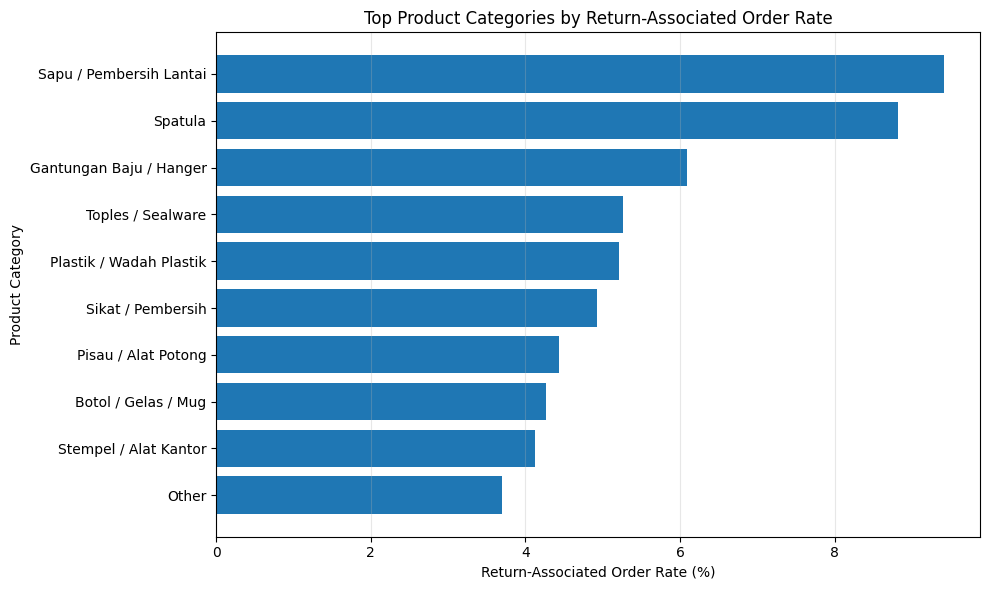

In [132]:
top_return_categories = category_returns_filtered.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_return_categories["product_category"],
    top_return_categories["return_associated_rate_pct"]
)

plt.title("Top Product Categories by Return-Associated Order Rate")
plt.xlabel("Return-Associated Order Rate (%)")
plt.ylabel("Product Category")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Category Return Behavior Insights

After restricting the analysis to categories with at least 50 completed orders, several categories show relatively higher return-associated order rates.

- **Sapu / Pembersih Lantai** records the highest return-associated order rate at **9.41%**, with 8 return-associated orders out of 85 completed orders.
- **Spatula** follows closely at **8.82%**, with 6 return-associated orders from 68 completed orders.
- **Gantungan Baju / Hanger** has a return-associated rate of **6.09%**, while **Toples / Sealware** and **Plastik / Wadah Plastik** record rates slightly above **5%**.
- Categories such as **Botol / Gelas / Mug** have a lower return-associated rate (**4.26%**) despite having a considerably larger transaction volume of 376 completed orders.

These results suggest that return-associated behavior varies across product categories and is not solely determined by transaction volume. Categories with relatively high return-associated rates may warrant further investigation into factors such as product quality, packaging, customer expectations, or shipping conditions.

Because returned quantities cannot be attributed to a specific product category within multi-category orders, these results represent **return-associated order rates rather than exact product-level return rates**.

----------

## 5. Geographic Performance Analysis

This section examines the geographic distribution of completed transactions to identify regions that contribute most strongly to transaction activity and payment value.

The analysis focuses on:

- Completed orders by province
- Transaction value by province
- Average Order Value (AOV) by province
- Top cities/regencies by completed orders

Only completed transactions are used to represent realized business activity.

### Province Performance

In [133]:
province_performance = (
    completed_orders
    .groupby("province")
    .agg(
        completed_orders=("order_id", "nunique"),
        total_payment_value=("total_payment", "sum"),
        average_order_value=("total_payment", "mean"),
        total_items=("total_quantity", "sum")
    )
    .reset_index()
)

province_performance["order_share_pct"] = (
    province_performance["completed_orders"]
    / len(completed_orders)
    * 100
).round(2)

province_performance["payment_share_pct"] = (
    province_performance["total_payment_value"]
    / completed_orders["total_payment"].sum()
    * 100
).round(2)

province_performance = province_performance.sort_values(
    "completed_orders",
    ascending=False
)

province_performance.head(15)

,province,completed_orders,total_payment_value,average_order_value,total_items,order_share_pct,payment_share_pct
8,JAWA BARAT,5897,276787756,"46,937.05",12247,32.89,26.32
2,BANTEN,3184,177861752,"55,861.10",7326,17.76,16.92
5,DKI JAKARTA,2535,135118501,"53,301.18",6713,14.14,12.85
10,JAWA TIMUR,1342,95248401,"70,974.96",3075,7.49,9.06
9,JAWA TENGAH,1302,99906841,"76,733.36",3194,7.26,9.50
32,SUMATERA SELATAN,534,40861929,"76,520.47",3628,2.98,3.89
17,LAMPUNG,416,22011153,"52,911.43",1126,2.32,2.09
7,JAMBI,285,15621508,"54,812.31",694,1.59,1.49
25,RIAU,269,14828015,"55,122.73",719,1.50,1.41
33,SUMATERA UTARA,240,18272044,"76,133.52",565,1.34,1.74


### Visualisasi Top Provinces by Completed Orders

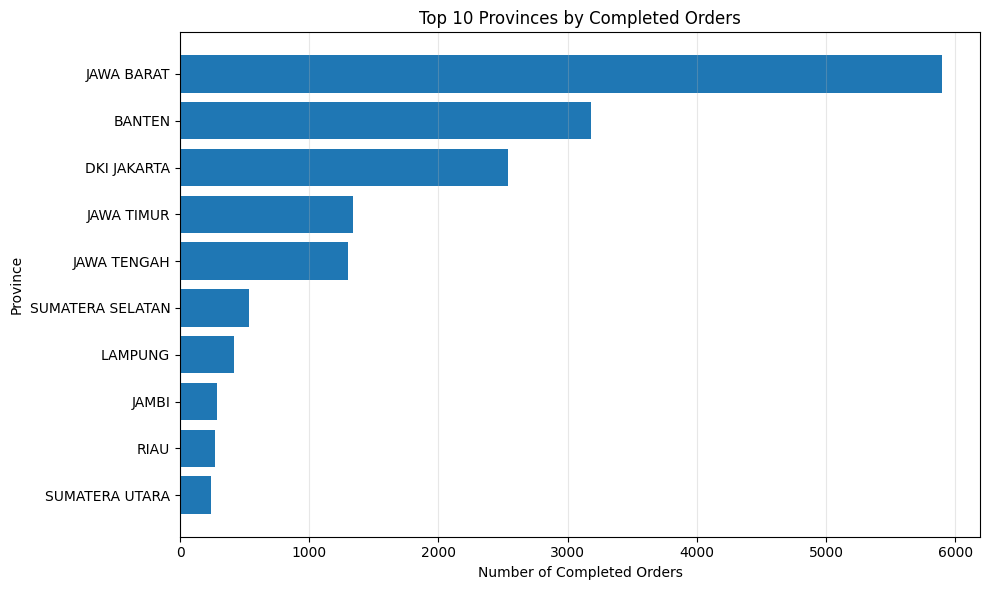

In [134]:
top_provinces_orders = province_performance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_provinces_orders["province"],
    top_provinces_orders["completed_orders"]
)

plt.title("Top 10 Provinces by Completed Orders")
plt.xlabel("Number of Completed Orders")
plt.ylabel("Province")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Province Order Distribution Insights

Completed transaction activity is strongly concentrated in several provinces.

- **Jawa Barat** records the highest transaction volume with **5,897 completed orders**, representing **32.89%** of all completed orders.
- **Banten** follows with **3,184 orders (17.76%)**, while **DKI Jakarta** contributes **2,535 orders (14.14%)**.
- Combined, these three provinces account for approximately **64.79% of completed orders**, indicating a strong geographic concentration of transaction activity.
- Transaction volumes decline considerably outside the leading provinces, with Jawa Timur and Jawa Tengah contributing **7.49%** and **7.26%**, respectively.

This concentration suggests that the business's completed transaction activity is primarily driven by markets in western Java, particularly Jawa Barat, Banten, and DKI Jakarta.

---------------

### Transaction Value by Province

Transaction value is analyzed alongside order volume to determine whether provinces with high transaction activity also generate the largest monetary contribution.

In [135]:
top_provinces_value = (
    province_performance
    .sort_values("total_payment_value", ascending=False)
    .head(10)
)

top_provinces_value[
    [
        "province",
        "completed_orders",
        "total_payment_value",
        "average_order_value",
        "payment_share_pct"
    ]
]

,province,completed_orders,total_payment_value,average_order_value,payment_share_pct
8,JAWA BARAT,5897,276787756,"46,937.05",26.32
2,BANTEN,3184,177861752,"55,861.10",16.92
5,DKI JAKARTA,2535,135118501,"53,301.18",12.85
9,JAWA TENGAH,1302,99906841,"76,733.36",9.50
10,JAWA TIMUR,1342,95248401,"70,974.96",9.06
32,SUMATERA SELATAN,534,40861929,"76,520.47",3.89
17,LAMPUNG,416,22011153,"52,911.43",2.09
0,BALI,162,21918090,"135,296.85",2.08
27,SULAWESI SELATAN,197,19513129,"99,051.42",1.86
33,SUMATERA UTARA,240,18272044,"76,133.52",1.74


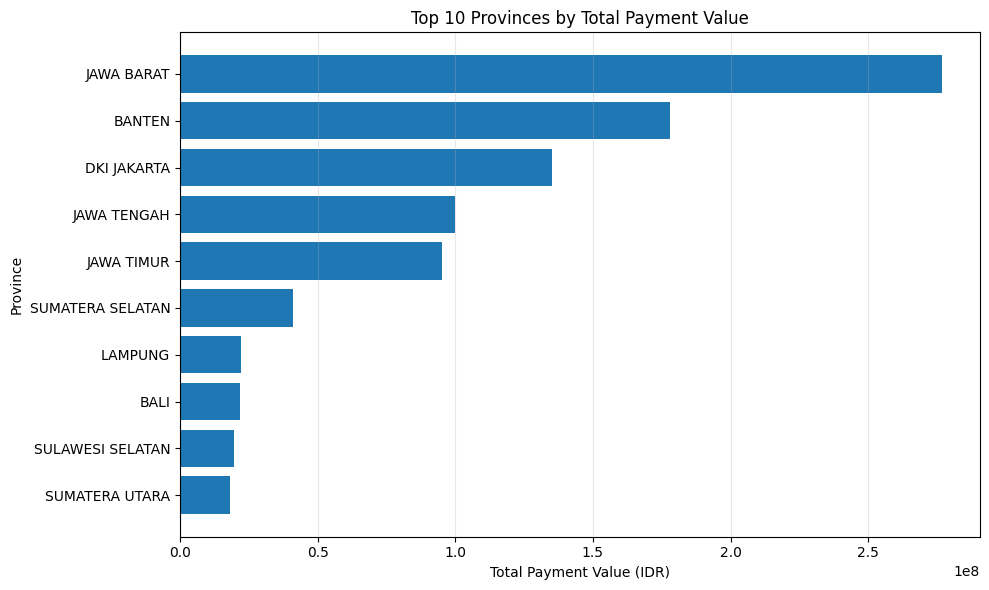

In [136]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_provinces_value["province"],
    top_provinces_value["total_payment_value"]
)

plt.title("Top 10 Provinces by Total Payment Value")
plt.xlabel("Total Payment Value (IDR)")
plt.ylabel("Province")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Province Transaction Value Insights

Transaction value is concentrated among the provinces with the highest transaction activity.

- **Jawa Barat** generates the highest total payment value at approximately **IDR 276.8 million**, contributing **26.32%** of total completed transaction value.
- **Banten** ranks second with approximately **IDR 177.9 million (16.92%)**, followed by **DKI Jakarta** with approximately **IDR 135.1 million (12.85%)**.
- Although **Jawa Barat** accounts for **32.89% of completed orders**, its payment contribution is lower at **26.32%**, suggesting a relatively lower average order value compared with several other provinces.
- **Bali** presents a contrasting pattern, contributing only a small share of completed orders while accounting for **2.08% of transaction value**, supported by a relatively high average order value.

Overall, the results indicate that high order volume does not always translate proportionally into high transaction value. Regional performance should therefore be evaluated using both transaction volume and Average Order Value (AOV).

-------------

#### Average Order Value by Province

Average Order Value (AOV) is compared across provinces to identify regions where completed transactions tend to have higher monetary value.

To reduce the influence of provinces with very small transaction volumes, only provinces with at least 100 completed orders are included in the comparison.

In [137]:
min_province_orders = 100

province_aov = (
    province_performance[
        province_performance["completed_orders"] >= min_province_orders
    ]
    .sort_values("average_order_value", ascending=False)
)

province_aov[
    [
        "province",
        "completed_orders",
        "average_order_value",
        "total_payment_value"
    ]
].head(10)

,province,completed_orders,average_order_value,total_payment_value
0,BALI,162,"135,296.85",21918090
27,SULAWESI SELATAN,197,"99,051.42",19513129
12,KALIMANTAN SELATAN,118,"84,240.58",9940388
9,JAWA TENGAH,1302,"76,733.36",99906841
32,SUMATERA SELATAN,534,"76,520.47",40861929
33,SUMATERA UTARA,240,"76,133.52",18272044
11,KALIMANTAN BARAT,169,"71,071.20",12011032
10,JAWA TIMUR,1342,"70,974.96",95248401
1,BANGKA BELITUNG,109,"56,944.17",6206914
3,BENGKULU,117,"56,006.13",6552717


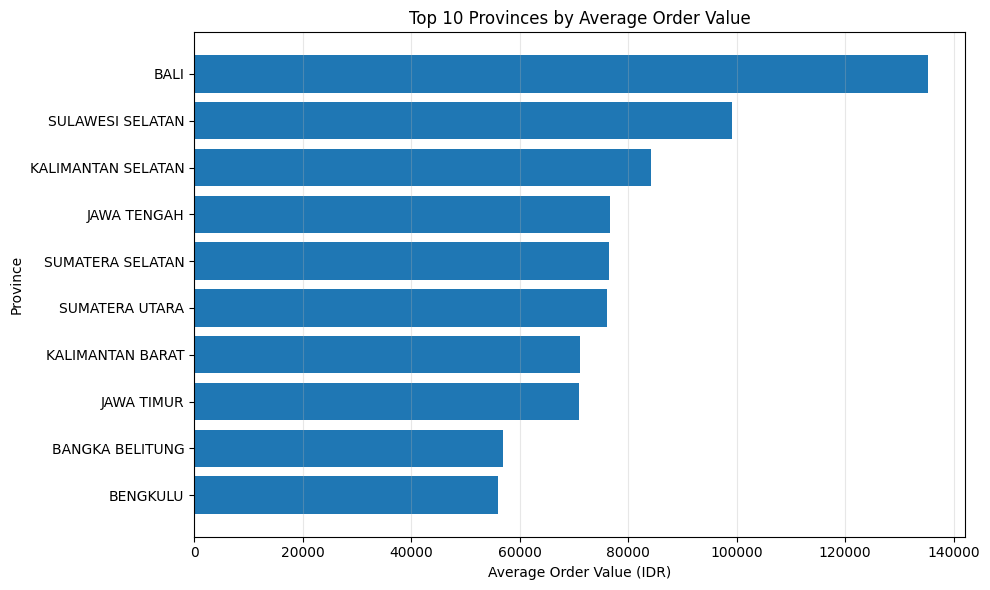

In [138]:
top_province_aov = province_aov.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_province_aov["province"],
    top_province_aov["average_order_value"]
)

plt.title("Top 10 Provinces by Average Order Value")
plt.xlabel("Average Order Value (IDR)")
plt.ylabel("Province")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Province Average Order Value Insights

Average Order Value reveals a different geographic pattern compared with transaction volume.

- **Bali** records the highest AOV at approximately **IDR 135.3 thousand**, despite having only 162 completed orders.
- **Sulawesi Selatan** follows with an AOV of approximately **IDR 99.1 thousand**, while **Kalimantan Selatan** records approximately **IDR 84.2 thousand**.
- In comparison, high-volume provinces such as **Jawa Barat** and **Banten** have lower average transaction values of approximately **IDR 46.9 thousand** and **IDR 55.9 thousand**, respectively.
- This indicates that provinces with the highest transaction volumes are not necessarily the regions where customers spend the most per completed order.

The results highlight two different dimensions of geographic performance: high-volume regions drive transaction frequency, while several lower-volume regions generate higher monetary value per transaction.

-----------

### Top Cities / Regencies by Completed Orders

The analysis is extended to the city/regency level to identify the local markets with the highest completed transaction activity.

In [139]:
city_performance = (
    completed_orders
    .groupby(["city_regency", "province"])
    .agg(
        completed_orders=("order_id", "nunique"),
        total_payment_value=("total_payment", "sum")
    )
    .reset_index()
)

city_performance["order_share_pct"] = (
    city_performance["completed_orders"]
    / len(completed_orders)
    * 100
).round(2)

city_performance = city_performance.sort_values(
    "completed_orders",
    ascending=False
)

city_performance.head(15)

,city_regency,province,completed_orders,total_payment_value,order_share_pct
52,KAB. BOGOR,JAWA BARAT,1061,58666903,5.92
297,KAB. TANGERANG,BANTEN,1012,61557031,5.64
401,KOTA TANGERANG,BANTEN,880,46541239,4.91
37,KAB. BEKASI,JAWA BARAT,732,25187473,4.08
402,KOTA TANGERANG SELATAN,BANTEN,701,36650441,3.91
349,KOTA JAKARTA BARAT,DKI JAKARTA,635,43381103,3.54
351,KOTA JAKARTA SELATAN,DKI JAKARTA,628,34585898,3.50
352,KOTA JAKARTA TIMUR,DKI JAKARTA,588,24471141,3.28
333,KOTA BEKASI,JAWA BARAT,552,22978551,3.08
345,KOTA DEPOK,JAWA BARAT,528,29437872,2.94


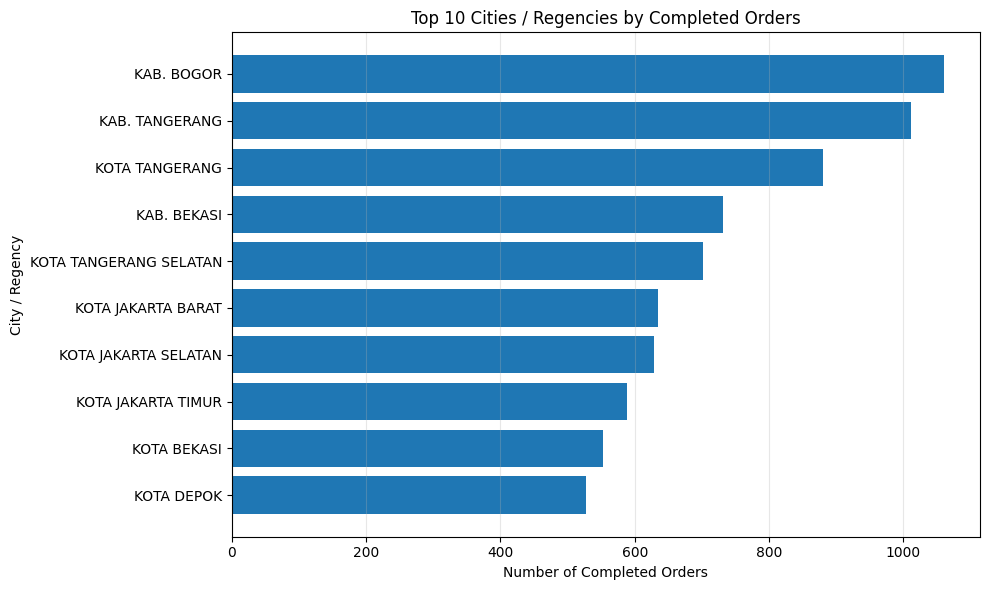

In [140]:
top_cities = city_performance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_cities["city_regency"],
    top_cities["completed_orders"]
)

plt.title("Top 10 Cities / Regencies by Completed Orders")
plt.xlabel("Number of Completed Orders")
plt.ylabel("City / Regency")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### City / Regency Performance Insights

Completed transaction activity is concentrated in several major cities and regencies, particularly around West Java, Banten, and DKI Jakarta.

- **Kab. Bogor** records the highest transaction volume with **1,061 completed orders (5.92%)**.
- **Kab. Tangerang** follows closely with **1,012 completed orders (5.64%)**, while **Kota Tangerang** ranks third with **880 completed orders (4.91%)**.
- Other major contributors include **Kab. Bekasi** with **732 completed orders (4.08%)** and **Kota Tangerang Selatan** with **701 completed orders (3.91%)**.
- Most of the highest-volume cities and regencies are located in **Jawa Barat, Banten, and DKI Jakarta**, consistent with the province-level results.

Overall, the geographic analysis indicates that completed transaction activity is concentrated around several major urban and metropolitan areas, with Bogor, Tangerang, Bekasi, and Jakarta contributing strongly to overall order volume.

### Geographic Performance Summary

Geographic performance shows a clear distinction between transaction volume and transaction value per order.

**Jawa Barat** is the largest market by completed orders and total payment value, supported by strong transaction activity in areas such as **Kab. Bogor** and **Kab. Bekasi**. **Banten** and **DKI Jakarta** also represent major transaction markets, with Tangerang and Jakarta contributing substantial order volumes.

However, Average Order Value shows a different pattern. Provinces such as **Bali, Sulawesi Selatan, and Kalimantan Selatan** record higher average transaction values despite having considerably lower transaction volumes.

These findings suggest that geographic markets contribute to business performance in different ways: some regions are primarily **high-volume markets**, while others show **higher spending per completed transaction**.

-------

# 6. Payment & Shipping Analysis

This section examines customer payment preferences and shipping behavior to understand how completed transactions are distributed across payment methods and delivery options.

The analysis focuses on:
- Payment method usage
- Transaction value by payment method
- Shipping option usage
- Shipping cost across shipping options

Only completed transactions are used to represent realized transaction activity.

## Payment Method Performance

Payment methods are analyzed based on the number of completed orders and their corresponding transaction value. This helps identify the payment methods most frequently used by customers and their contribution to completed transaction value.

In [141]:
payment_performance = (
    completed_orders
    .groupby("payment_method")
    .agg(
        completed_orders=("order_id", "nunique"),
        total_payment_value=("total_payment", "sum"),
        average_order_value=("total_payment", "mean")
    )
    .reset_index()
)

payment_performance["order_share_pct"] = (
    payment_performance["completed_orders"]
    / len(completed_orders)
    * 100
).round(2)

payment_performance["payment_share_pct"] = (
    payment_performance["total_payment_value"]
    / completed_orders["total_payment"].sum()
    * 100
).round(2)

payment_performance = payment_performance.sort_values(
    "completed_orders",
    ascending=False
)

payment_performance

,payment_method,completed_orders,total_payment_value,average_order_value,order_share_pct,payment_share_pct
2,COD (Bayar di Tempat),9924,406079008,"40,918.88",55.35,38.62
9,Saldo ShopeePay,3364,239168135,"71,096.35",18.76,22.75
6,Online Payment,2572,242993839,"94,476.61",14.35,23.11
8,SPayLater,1262,97033916,"76,889.00",7.04,9.23
10,SeaBank Bayar Instan,551,36377474,"66,020.82",3.07,3.46
5,Kartu Kredit/Debit,193,19393054,"100,482.15",1.08,1.84
4,Indomaret/i.Saku,22,4344947,"197,497.59",0.12,0.41
0,Alfamart/Alfamidi/Dan+Dan,19,5170730,"272,143.68",0.11,0.49
7,Pembayaran dibebaskan,17,0,0.00,0.09,0.00
3,Cicilan Kartu Kredit,3,789704,"263,234.67",0.02,0.08


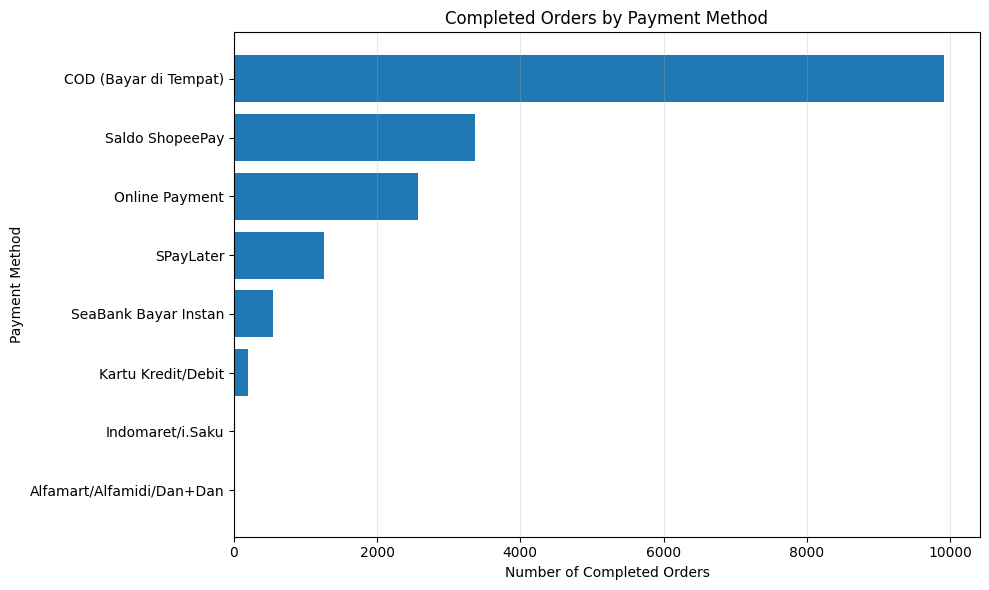

In [142]:
top_payment_methods = payment_performance.head(8)

plt.figure(figsize=(10, 6))

plt.barh(
    top_payment_methods["payment_method"],
    top_payment_methods["completed_orders"]
)

plt.title("Completed Orders by Payment Method")
plt.xlabel("Number of Completed Orders")
plt.ylabel("Payment Method")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Payment Method Insights

Payment behavior is highly concentrated among a few payment methods.

- **COD (Bayar di Tempat)** is the dominant payment method, accounting for **9,924 completed orders (55.35%)**.
- **Saldo ShopeePay** ranks second with **3,364 orders (18.76%)**, followed by **Online Payment** with **2,572 orders (14.35%)**.
- Together, these three methods account for approximately **88% of completed orders**, indicating that transaction activity is strongly concentrated among these payment options.
- Although COD has the highest order volume, its Average Order Value is approximately **IDR 40.9 thousand**, substantially lower than Online Payment at approximately **IDR 94.5 thousand**.

This suggests that the most frequently used payment method does not necessarily generate the highest transaction value per order.

-------------

### Transaction Value by Payment Method

Order volume alone does not fully represent the monetary contribution of each payment method. Therefore, total payment value is compared across payment methods to determine which methods contribute most strongly to completed transaction value.

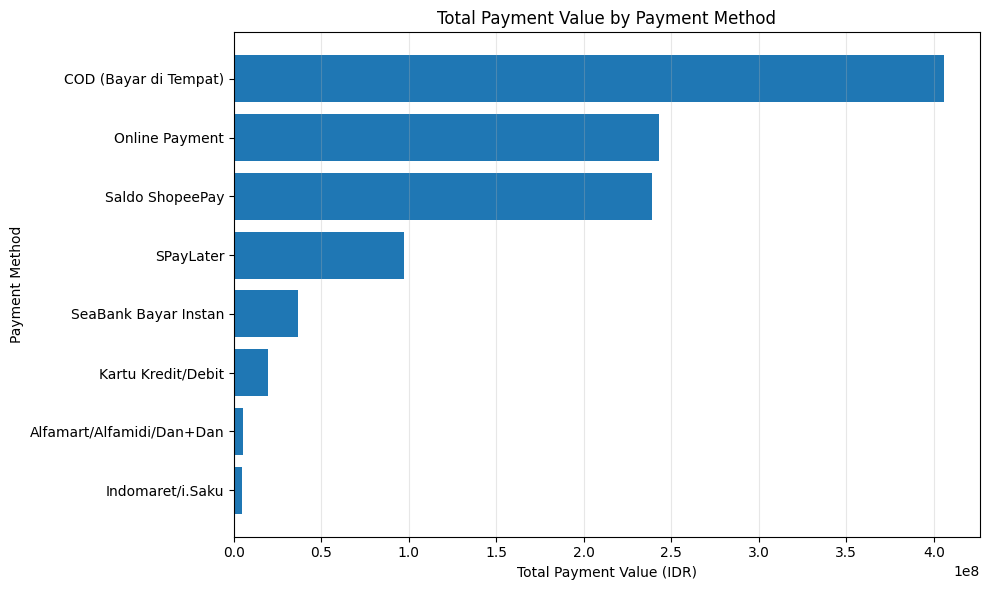

In [143]:
payment_value = payment_performance.sort_values(
    "total_payment_value",
    ascending=False
).head(8)

plt.figure(figsize=(10, 6))

plt.barh(
    payment_value["payment_method"],
    payment_value["total_payment_value"]
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Total Payment Value (IDR)")
plt.ylabel("Payment Method")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Payment Transaction Value Insights

The transaction value distribution shows that payment method popularity and monetary contribution are not identical.

- **COD (Bayar di Tempat)** remains the largest contributor, generating approximately **IDR 406.8 million**, or **38.62%** of completed transaction value.
- **Online Payment** contributes approximately **IDR 243.0 million (23.11%)**, despite representing only **14.35% of completed orders**.
- **Saldo ShopeePay** contributes approximately **IDR 239.2 million (22.75%)** from **18.76% of completed orders**.
- Online Payment therefore generates a disproportionately high share of transaction value relative to its order volume, which is consistent with its relatively high Average Order Value.

Overall, COD dominates transaction volume, while digital payment methods—particularly Online Payment—are associated with higher-value transactions.

------------------

## Shipping Option Performance

Shipping options are analyzed to understand customer delivery preferences and the distribution of completed transactions across available shipping services.

The analysis compares order volume, transaction value, and estimated shipping cost across shipping options.

In [144]:
shipping_performance = (
    completed_orders
    .groupby("shipping_option")
    .agg(
        completed_orders=("order_id", "nunique"),
        total_payment_value=("total_payment", "sum"),
        average_shipping_cost=("estimated_shipping_cost", "mean"),
        total_shipping_cost=("estimated_shipping_cost", "sum")
    )
    .reset_index()
)

shipping_performance["order_share_pct"] = (
    shipping_performance["completed_orders"]
    / len(completed_orders)
    * 100
).round(2)

shipping_performance = shipping_performance.sort_values(
    "completed_orders",
    ascending=False
)

shipping_performance

,shipping_option,completed_orders,total_payment_value,average_shipping_cost,total_shipping_cost,order_share_pct
10,Hemat Kargo-SPX Hemat,11159,505127876,"15,809.61",176419465,62.24
27,Reguler (Cashless)-SPX Standard,4240,156993161,"14,214.62",60269996,23.65
29,SPX Hemat,476,16409925,"17,745.80",8447000,2.65
26,Reguler (Cashless)-JNE Reguler,331,16130554,"16,786.69",5556395,1.85
13,Instant (Versi Lama)-SPX Instant (Versi Lama),292,62073976,"40,000.00",11680000,1.63
36,Same Day-SPX Sameday,272,30596009,"23,303.31",6338500,1.52
23,Kargo-JNE Trucking (JTR),172,72061474,"46,221.11",7950031,0.96
34,SPX Standard,168,8437648,"19,846.43",3334200,0.94
22,Kargo-J&T Cargo,140,72732985,"46,356.59",6489923,0.78
8,Hemat Kargo-J&T Economy,138,13390007,"47,817.39",6598800,0.77


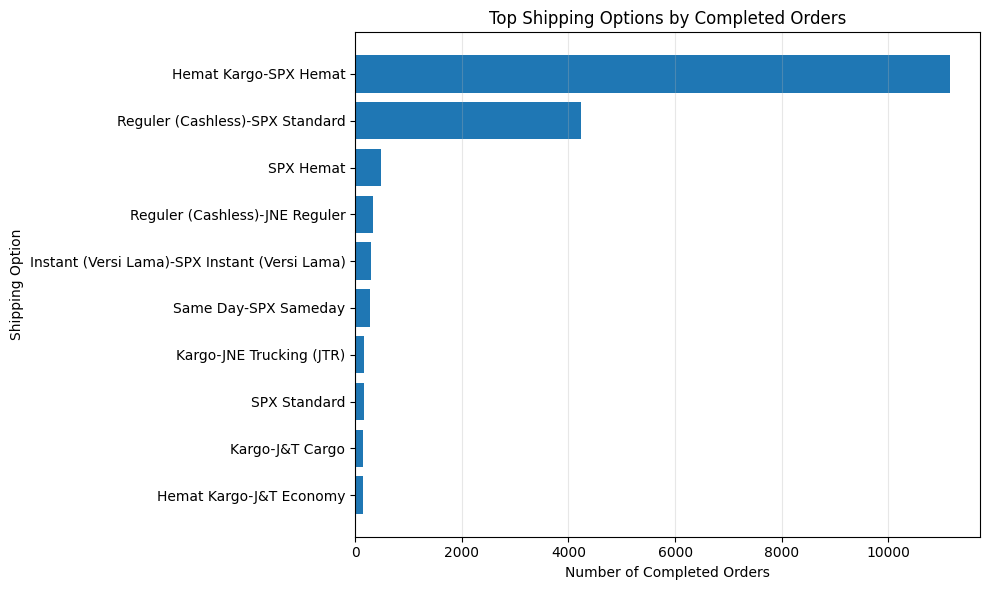

In [145]:
top_shipping_options = shipping_performance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_shipping_options["shipping_option"],
    top_shipping_options["completed_orders"]
)

plt.title("Top Shipping Options by Completed Orders")
plt.xlabel("Number of Completed Orders")
plt.ylabel("Shipping Option")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Shipping Option Insights

Shipping activity is highly concentrated among a small number of delivery options.

- **Hemat Kargo-SPX Hemat** is the dominant shipping option with **11,159 completed orders (62.24%)**.
- **Reguler (Cashless)-SPX Standard** ranks second with **4,240 orders (23.65%)**.
- Together, these two options account for approximately **85.9% of completed orders**, indicating a strong concentration in economical and standard delivery services.
- Other shipping options individually represent only a small proportion of completed transactions.

Overall, customers appear to favor economical and standard shipping services over less frequently used alternatives.

--------

### Shipping Cost Comparison

Average estimated shipping cost is compared across frequently used shipping options to examine differences in delivery cost while avoiding excessive influence from rarely used services.

In [146]:
shipping_cost_comparison = (
    shipping_performance[
        shipping_performance["completed_orders"] >= 50
    ]
    .sort_values("average_shipping_cost", ascending=False)
)

shipping_cost_comparison[
    [
        "shipping_option",
        "completed_orders",
        "average_shipping_cost"
    ]
]

,shipping_option,completed_orders,average_shipping_cost
8,Hemat Kargo-J&T Economy,138,"47,817.39"
22,Kargo-J&T Cargo,140,"46,356.59"
23,Kargo-JNE Trucking (JTR),172,"46,221.11"
13,Instant (Versi Lama)-SPX Instant (Versi Lama),292,"40,000.00"
7,Hemat Kargo-J&T Cargo,63,"39,692.06"
25,Reguler (Cashless)-J&T Express,95,"37,287.36"
0,Agen SPX Express,75,"27,706.67"
36,Same Day-SPX Sameday,272,"23,303.31"
34,SPX Standard,168,"19,846.43"
29,SPX Hemat,476,"17,745.80"


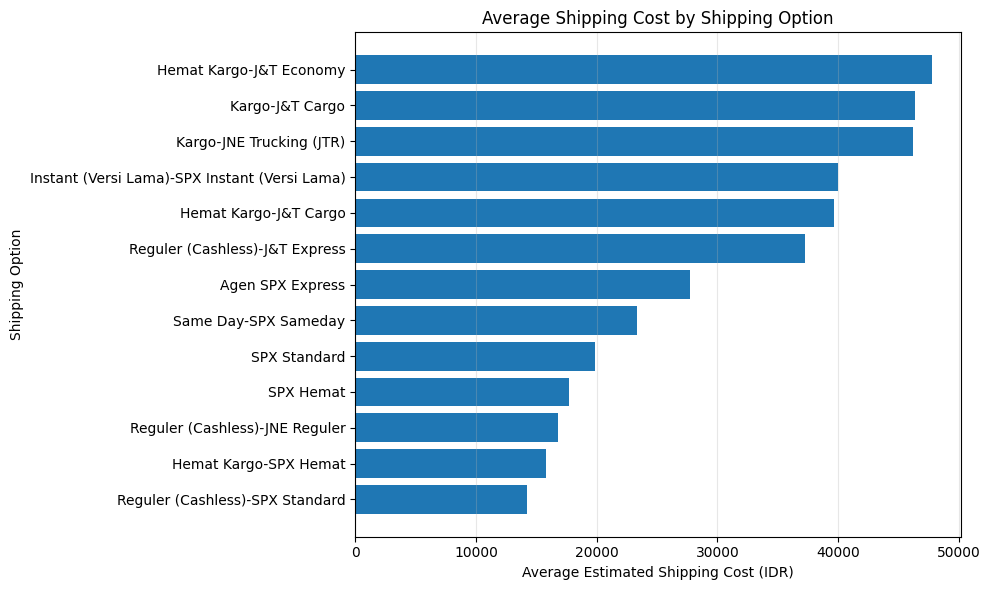

In [147]:
plt.figure(figsize=(10, 6))

plt.barh(
    shipping_cost_comparison["shipping_option"],
    shipping_cost_comparison["average_shipping_cost"]
)

plt.title("Average Shipping Cost by Shipping Option")
plt.xlabel("Average Estimated Shipping Cost (IDR)")
plt.ylabel("Shipping Option")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Shipping Cost Insights

Average shipping costs vary considerably across frequently used shipping options.

- **Hemat Kargo-J&T Economy** has the highest average estimated shipping cost at approximately **IDR 47.8 thousand**, followed by **Kargo-J&T Cargo** at approximately **IDR 46.4 thousand**.
- In contrast, the two most frequently used shipping options have relatively lower average costs: **SPX Standard** at approximately **IDR 14.2 thousand** and **SPX Hemat** at approximately **IDR 17.5 thousand**.
- The dominance of SPX Hemat and SPX Standard in order volume, combined with their relatively low average shipping costs, indicates that lower-cost delivery options are strongly represented among completed transactions.

However, these results describe an association between shipping option usage and estimated shipping cost and should not be interpreted as evidence that lower shipping costs directly cause customers to select a particular shipping option.

--------

## 7. Cancellation & Return Analysis

This section examines unsuccessful and returned transactions to identify potential operational and customer-related issues within the e-commerce process.

The analysis focuses on:
- Cancellation reasons
- Cancellation patterns across selected transaction characteristics
- Return behavior among completed transactions

Cancellation and return behavior are analyzed separately because they represent different stages of the transaction process.

### Cancellation Reason Analysis

Cancelled transactions are analyzed to identify the most frequently recorded reasons for order cancellation.

Understanding the distribution of cancellation reasons helps highlight potential issues related to payment, customer decisions, inventory, logistics, or other transaction processes.

In [148]:
cancelled_orders = df[
    df["order_status_group"] == "Cancelled"
].copy()

print(f"Total Cancelled Orders: {len(cancelled_orders):,}")
print(
    f"Cancellation Rate: "
    f"{len(cancelled_orders) / len(df) * 100:.2f}%"
)

Total Cancelled Orders: 2,830
Cancellation Rate: 13.57%


In [149]:
cancellation_reasons = (
    cancelled_orders["cancellation_reason"]
    .value_counts()
    .rename_axis("cancellation_reason")
    .reset_index(name="cancelled_orders")
)

cancellation_reasons["share_pct"] = (
    cancellation_reasons["cancelled_orders"]
    / len(cancelled_orders)
    * 100
).round(2)

cancellation_reasons

,cancellation_reason,cancelled_orders,share_pct
0,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,662,23.39
1,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,558,19.72
2,Dibatalkan secara otomatis oleh sistem. Alasan...,447,15.80
3,Dibatalkan oleh Pembeli. Alasan: Need to chang...,306,10.81
4,Dibatalkan secara otomatis oleh sistem. Alasan...,255,9.01
5,Dibatalkan secara otomatis oleh sistem. Alasan...,113,3.99
6,Dibatalkan oleh Pembeli. Alasan: Perlu menguba...,113,3.99
7,Dibatalkan oleh Pembeli. Alasan: Perlu menguba...,79,2.79
8,Dibatalkan secara otomatis oleh sistem. Alasan...,63,2.23
9,Dibatalkan oleh Pembeli. Alasan: Lainnya,48,1.70


**Top Cancellation Reasons**

The most frequent cancellation reasons are visualized to identify the main recorded factors associated with unsuccessful transactions.

Because cancellation descriptions are relatively detailed, the analysis focuses on the ten most frequently recorded reasons.

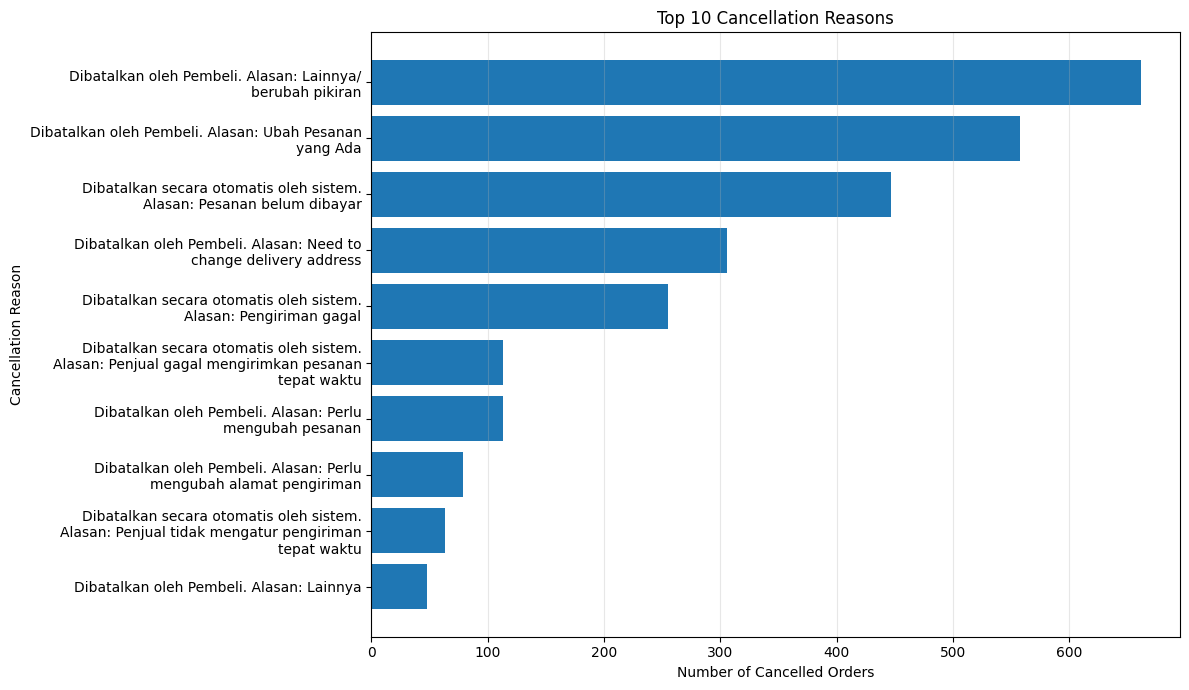

In [150]:
import textwrap

top_cancellation_reasons = cancellation_reasons.head(10).copy()

top_cancellation_reasons["reason_short"] = (
    top_cancellation_reasons["cancellation_reason"]
    .apply(lambda x: "\n".join(textwrap.wrap(str(x), width=45)))
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_cancellation_reasons["reason_short"],
    top_cancellation_reasons["cancelled_orders"]
)

plt.title("Top 10 Cancellation Reasons")
plt.xlabel("Number of Cancelled Orders")
plt.ylabel("Cancellation Reason")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Cancellation Reason Insights

Cancellation reasons are distributed across several different causes rather than being dominated by a single reason.

- The most frequently recorded cancellation reason accounts for **662 orders (23.39%)** of all cancelled transactions.
- The second and third most frequent reasons account for **558 orders (19.72%)** and **447 orders (15.80%)**, respectively.
- Together, the top three recorded reasons represent approximately **58.9% of all cancellations**.
- Several cancellation reasons are initiated by buyers, while others are associated with automatic system cancellations or seller-related issues.

The results indicate that cancellation behavior involves multiple stages of the transaction process. Further analysis of broader cancellation groups can help distinguish customer-driven, seller-driven, and system-driven cancellations.

--------

### Cancellation Type Analysis

Detailed cancellation reasons are grouped into broader cancellation types to provide a clearer view of where cancellations originate.

This analysis helps distinguish whether cancellations are primarily associated with buyers, sellers, or automatic system processes.

In [151]:
def classify_cancellation(reason):
    reason = str(reason).lower()

    if "dibatalkan oleh pembeli" in reason:
        return "Buyer"
    elif "dibatalkan oleh penjual" in reason:
        return "Seller"
    elif "dibatalkan secara otomatis oleh sistem" in reason:
        return "System"
    else:
        return "Other"


cancelled_orders["cancellation_type"] = (
    cancelled_orders["cancellation_reason"]
    .apply(classify_cancellation)
)

cancelled_orders[
    ["cancellation_reason", "cancellation_type"]
].head(15)

,cancellation_reason,cancellation_type
4,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Buyer
6,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Buyer
8,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Buyer
10,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,Buyer
11,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,Buyer
14,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Buyer
21,Dibatalkan secara otomatis oleh sistem. Alasan...,System
31,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,Buyer
34,Dibatalkan secara otomatis oleh sistem. Alasan...,System
38,Dibatalkan oleh Pembeli. Alasan: Need to chang...,Buyer


In [152]:
cancellation_type_summary = (
    cancelled_orders["cancellation_type"]
    .value_counts()
    .rename_axis("cancellation_type")
    .reset_index(name="cancelled_orders")
)

cancellation_type_summary["share_pct"] = (
    cancellation_type_summary["cancelled_orders"]
    / len(cancelled_orders)
    * 100
).round(2)

cancellation_type_summary

,cancellation_type,cancelled_orders,share_pct
0,Buyer,1912,67.56
1,System,904,31.94
2,Seller,14,0.49


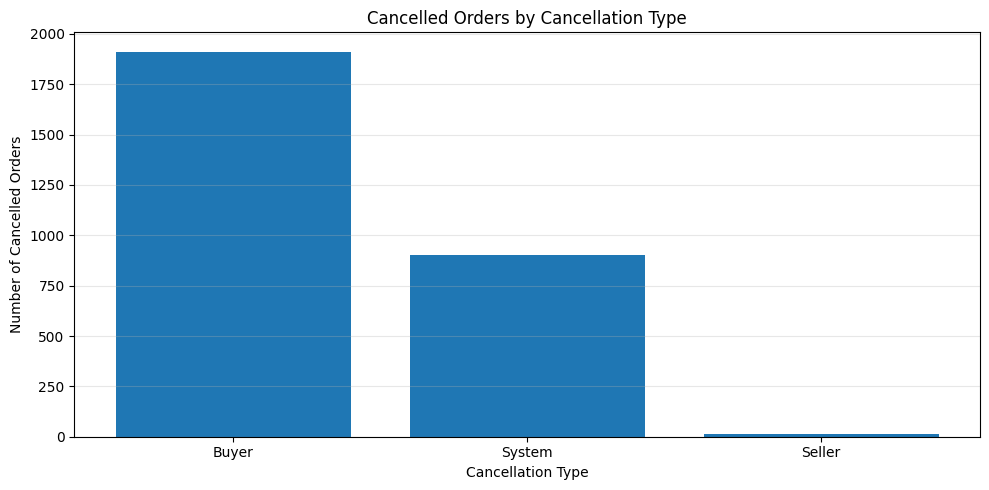

In [153]:
plt.figure(figsize=(10, 5))

plt.bar(
    cancellation_type_summary["cancellation_type"],
    cancellation_type_summary["cancelled_orders"]
)

plt.title("Cancelled Orders by Cancellation Type")
plt.xlabel("Cancellation Type")
plt.ylabel("Number of Cancelled Orders")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Cancellation Type Insights

Cancellation type analysis shows that cancellations are primarily associated with buyer decisions and automatic system processes.

- **Buyer-related cancellations** account for **1,912 orders (67.56%)**, making them the dominant source of cancelled transactions.
- **System-related cancellations** account for **904 orders (31.94%)**, representing nearly one-third of all cancellations.
- **Seller-related cancellations** are relatively uncommon, with only **14 orders (0.49%)**.
- Overall, approximately **99.5% of cancellations are associated with buyers or automatic system processes**, while seller-related cancellations contribute only a very small proportion.

These findings suggest that further investigation into buyer cancellation reasons and automatic system cancellation triggers may provide the greatest opportunity for understanding and potentially reducing cancelled transactions.

------------

### Return Analysis

Return behavior is analyzed to understand how frequently completed transactions contain returned items and how returned quantities are distributed across completed orders.

Unlike the previous category-level return analysis, this section focuses on the overall return behavior of completed transactions.

In [157]:
return_summary = pd.DataFrame({
    "metric": [
        "Completed Orders",
        "Orders with Returns",
        "Orders without Returns",
        "Total Items Sold",
        "Total Returned Items"
    ],
    "value": [
        completed_orders["order_id"].nunique(),

        completed_orders.loc[
            completed_orders["has_return"] == 1,
            "order_id"
        ].nunique(),

        completed_orders.loc[
            completed_orders["has_return"] == 0,
            "order_id"
        ].nunique(),

        completed_orders["total_quantity"].sum(),

        completed_orders["total_returned_quantity"].sum()
    ]
})

return_summary

,metric,value
0,Completed Orders,17929
1,Orders with Returns,157
2,Orders without Returns,17772
3,Total Items Sold,44546
4,Total Returned Items,370


In [158]:
orders_with_return = completed_orders.loc[
    completed_orders["has_return"] == 1,
    "order_id"
].nunique()

order_return_rate = (
    orders_with_return
    / completed_orders["order_id"].nunique()
    * 100
)

item_return_rate = (
    completed_orders["total_returned_quantity"].sum()
    / completed_orders["total_quantity"].sum()
    * 100
)

print(f"Orders with Returns : {orders_with_return:,}")
print(f"Order Return Rate   : {order_return_rate:.2f}%")
print(f"Item Return Rate    : {item_return_rate:.2f}%")

Orders with Returns : 157
Order Return Rate   : 0.88%
Item Return Rate    : 0.83%


**Overall Return Behavior**

The overall return rate is examined from both an order-level and item-level perspective to understand the scale of returned transactions relative to completed sales.

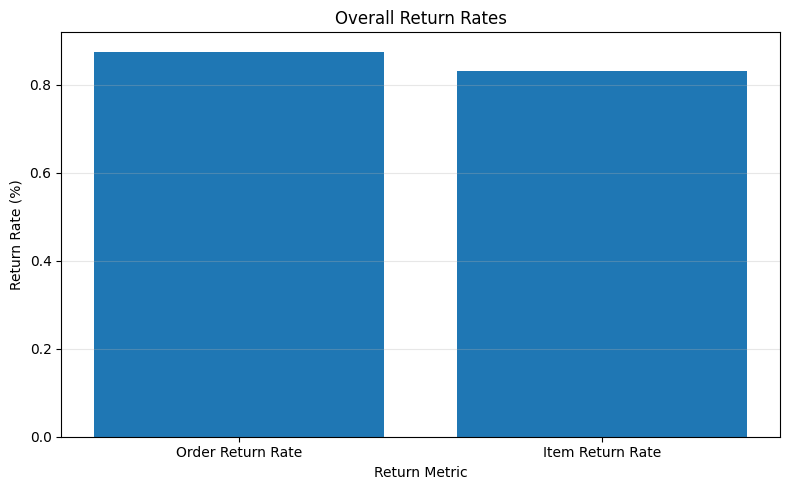

In [159]:
return_rates = pd.DataFrame({
    "Return Metric": [
        "Order Return Rate",
        "Item Return Rate"
    ],
    "Rate (%)": [
        order_return_rate,
        item_return_rate
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    return_rates["Return Metric"],
    return_rates["Rate (%)"]
)

plt.title("Overall Return Rates")
plt.xlabel("Return Metric")
plt.ylabel("Return Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Return Analysis Insights

Returns represent a relatively small proportion of completed transaction activity.

- Out of **17,929 completed orders**, only **157 orders contained returned items**, resulting in an **Order Return Rate of 0.88%**.
- A total of **370 items were returned** from **44,546 items sold**, corresponding to an **Item Return Rate of 0.83%**.
- Both return metrics remain below **1%**, indicating that returned transactions represent a relatively small share of completed sales activity.
- The similarity between the order-level and item-level return rates suggests that returns are not heavily concentrated in unusually large orders.

Combined with the earlier category-level analysis, these results indicate that overall return activity is limited, although certain product categories may still exhibit relatively higher return-associated order rates.

---------------

## 8. Final EDA Insights

This section summarizes the key findings from the exploratory data analysis across business performance, temporal trends, product categories, geographic markets, payment and shipping behavior, cancellations, and returns.

The objective is to consolidate the most relevant findings into a concise business-oriented summary before proceeding to further analysis and dashboard development.

In [ ]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Completed Orders",
        "Cancelled Orders",
        "Completion Rate",
        "Cancellation Rate",
        "Completed Transaction Value",
        "Average Order Value",
        "Total Items Sold",
        "Order Return Rate",
        "Item Return Rate"
    ],
    "Value": [
        f"{df['order_id'].nunique():,}",
        f"{completed_orders['order_id'].nunique():,}",
        f"{len(cancelled_orders):,}",
        f"{completed_orders['order_id'].nunique() / df['order_id'].nunique() * 100:.2f}%",
        f"{len(cancelled_orders) / df['order_id'].nunique() * 100:.2f}%",
        f"IDR {completed_orders['total_payment'].sum():,.0f}",
        f"IDR {completed_orders['total_payment'].mean():,.0f}",
        f"{completed_orders['total_quantity'].sum():,}",
        f"{order_return_rate:.2f}%",
        f"{item_return_rate:.2f}%"
    ]
})

final_summary

### Key Business Findings

#### 1. Business Performance
The dataset shows substantial completed transaction activity, but cancellations remain an important component of overall order outcomes. Monthly performance also fluctuates considerably, indicating that transaction activity is not stable throughout the observed period.

#### 2. Monthly Performance
Completed order volume and transaction value do not always move in the same direction. Changes in Average Order Value (AOV) help explain why higher order volume does not necessarily result in proportionally higher transaction value.

#### 3. Product & Category Performance
Product demand is concentrated among several categories. **Celengan** is the most frequently appearing category in completed orders, while **Seal / Baut / Roof** generates the highest estimated category-level transaction value despite having substantially fewer orders. This demonstrates that category popularity and monetary contribution represent different aspects of product performance.

#### 4. Geographic Performance
Completed transaction activity is geographically concentrated, particularly in major markets such as **Jawa Barat, Banten, and DKI Jakarta**. However, provinces with the highest order volumes are not necessarily those with the highest Average Order Value, indicating differences in customer purchasing behavior across regions.

#### 5. Payment & Shipping Behavior
**COD (Bayar di Tempat)** is the dominant payment method among completed transactions. Shipping activity is also highly concentrated in several frequently used services, while average estimated shipping costs vary substantially across shipping options.

#### 6. Cancellation Behavior
A total of **2,830 orders were cancelled**, corresponding to a **13.57% cancellation rate**. Buyer-related cancellations account for **67.56%** of cancelled transactions, followed by automatic system cancellations at **31.94%**, while seller-related cancellations represent only **0.49%**.

#### 7. Return Behavior
Returns are relatively uncommon among completed transactions. Only **157 of 17,929 completed orders** contain returned items, resulting in an **Order Return Rate of 0.88%**. At the item level, **370 of 44,546 sold items** were returned, corresponding to an **Item Return Rate of 0.83%**.

### Overall Conclusion

The exploratory analysis indicates that business performance is driven by multiple dimensions rather than transaction volume alone. Product mix, regional purchasing behavior, payment preferences, shipping choices, and cancellation patterns all contribute to differences in realized transaction value.

The findings also highlight several areas for further business monitoring, particularly monthly performance fluctuations, high-value product categories, geographic concentration, buyer-related cancellations, and shipping cost differences.

These insights provide the analytical foundation for the next stage of the project: developing a business intelligence dashboard for monitoring key performance indicators and supporting data-driven decision making.

In [ ]:
pp